In [1]:
# %matplotlib inline
import os
import stim
import sinter
import matplotlib.pyplot as plt
import pymatching
from typing import List

# stim's method for 1 round of d=3 surface code

# source code: https://github.com/quantumlib/Stim/blob/main/src/stim/gen/gen_surface_code.cc

In [2]:
surface_code_circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    rounds=1,
    distance=3,
    after_clifford_depolarization=0.00,
    after_reset_flip_probability=0.00,
    before_measure_flip_probability=0.00,
    before_round_data_depolarization=0.00)

In [3]:
print(repr(surface_code_circuit))

stim.Circuit('''
    QUBIT_COORDS(1, 1) 1
    QUBIT_COORDS(2, 0) 2
    QUBIT_COORDS(3, 1) 3
    QUBIT_COORDS(5, 1) 5
    QUBIT_COORDS(1, 3) 8
    QUBIT_COORDS(2, 2) 9
    QUBIT_COORDS(3, 3) 10
    QUBIT_COORDS(4, 2) 11
    QUBIT_COORDS(5, 3) 12
    QUBIT_COORDS(6, 2) 13
    QUBIT_COORDS(0, 4) 14
    QUBIT_COORDS(1, 5) 15
    QUBIT_COORDS(2, 4) 16
    QUBIT_COORDS(3, 5) 17
    QUBIT_COORDS(4, 4) 18
    QUBIT_COORDS(5, 5) 19
    QUBIT_COORDS(4, 6) 25
    R 1 3 5 8 10 12 15 17 19 2 9 11 13 14 16 18 25
    TICK
    H 2 11 16 25
    TICK
    CX 2 3 16 17 11 12 15 14 10 9 19 18
    TICK
    CX 2 1 16 15 11 10 8 14 3 9 12 18
    TICK
    CX 16 10 11 5 25 19 8 9 17 18 12 13
    TICK
    CX 16 8 11 3 25 17 1 9 10 18 5 13
    TICK
    H 2 11 16 25
    TICK
    MR 2 9 11 13 14 16 18 25
    DETECTOR(0, 4, 0) rec[-4]
    DETECTOR(2, 2, 0) rec[-7]
    DETECTOR(4, 4, 0) rec[-2]
    DETECTOR(6, 2, 0) rec[-5]
    M 1 3 5 8 10 12 15 17 19
    DETECTOR(0, 4, 1) rec[-3] rec[-6] rec[-13]
    DETECTOR(2, 2,

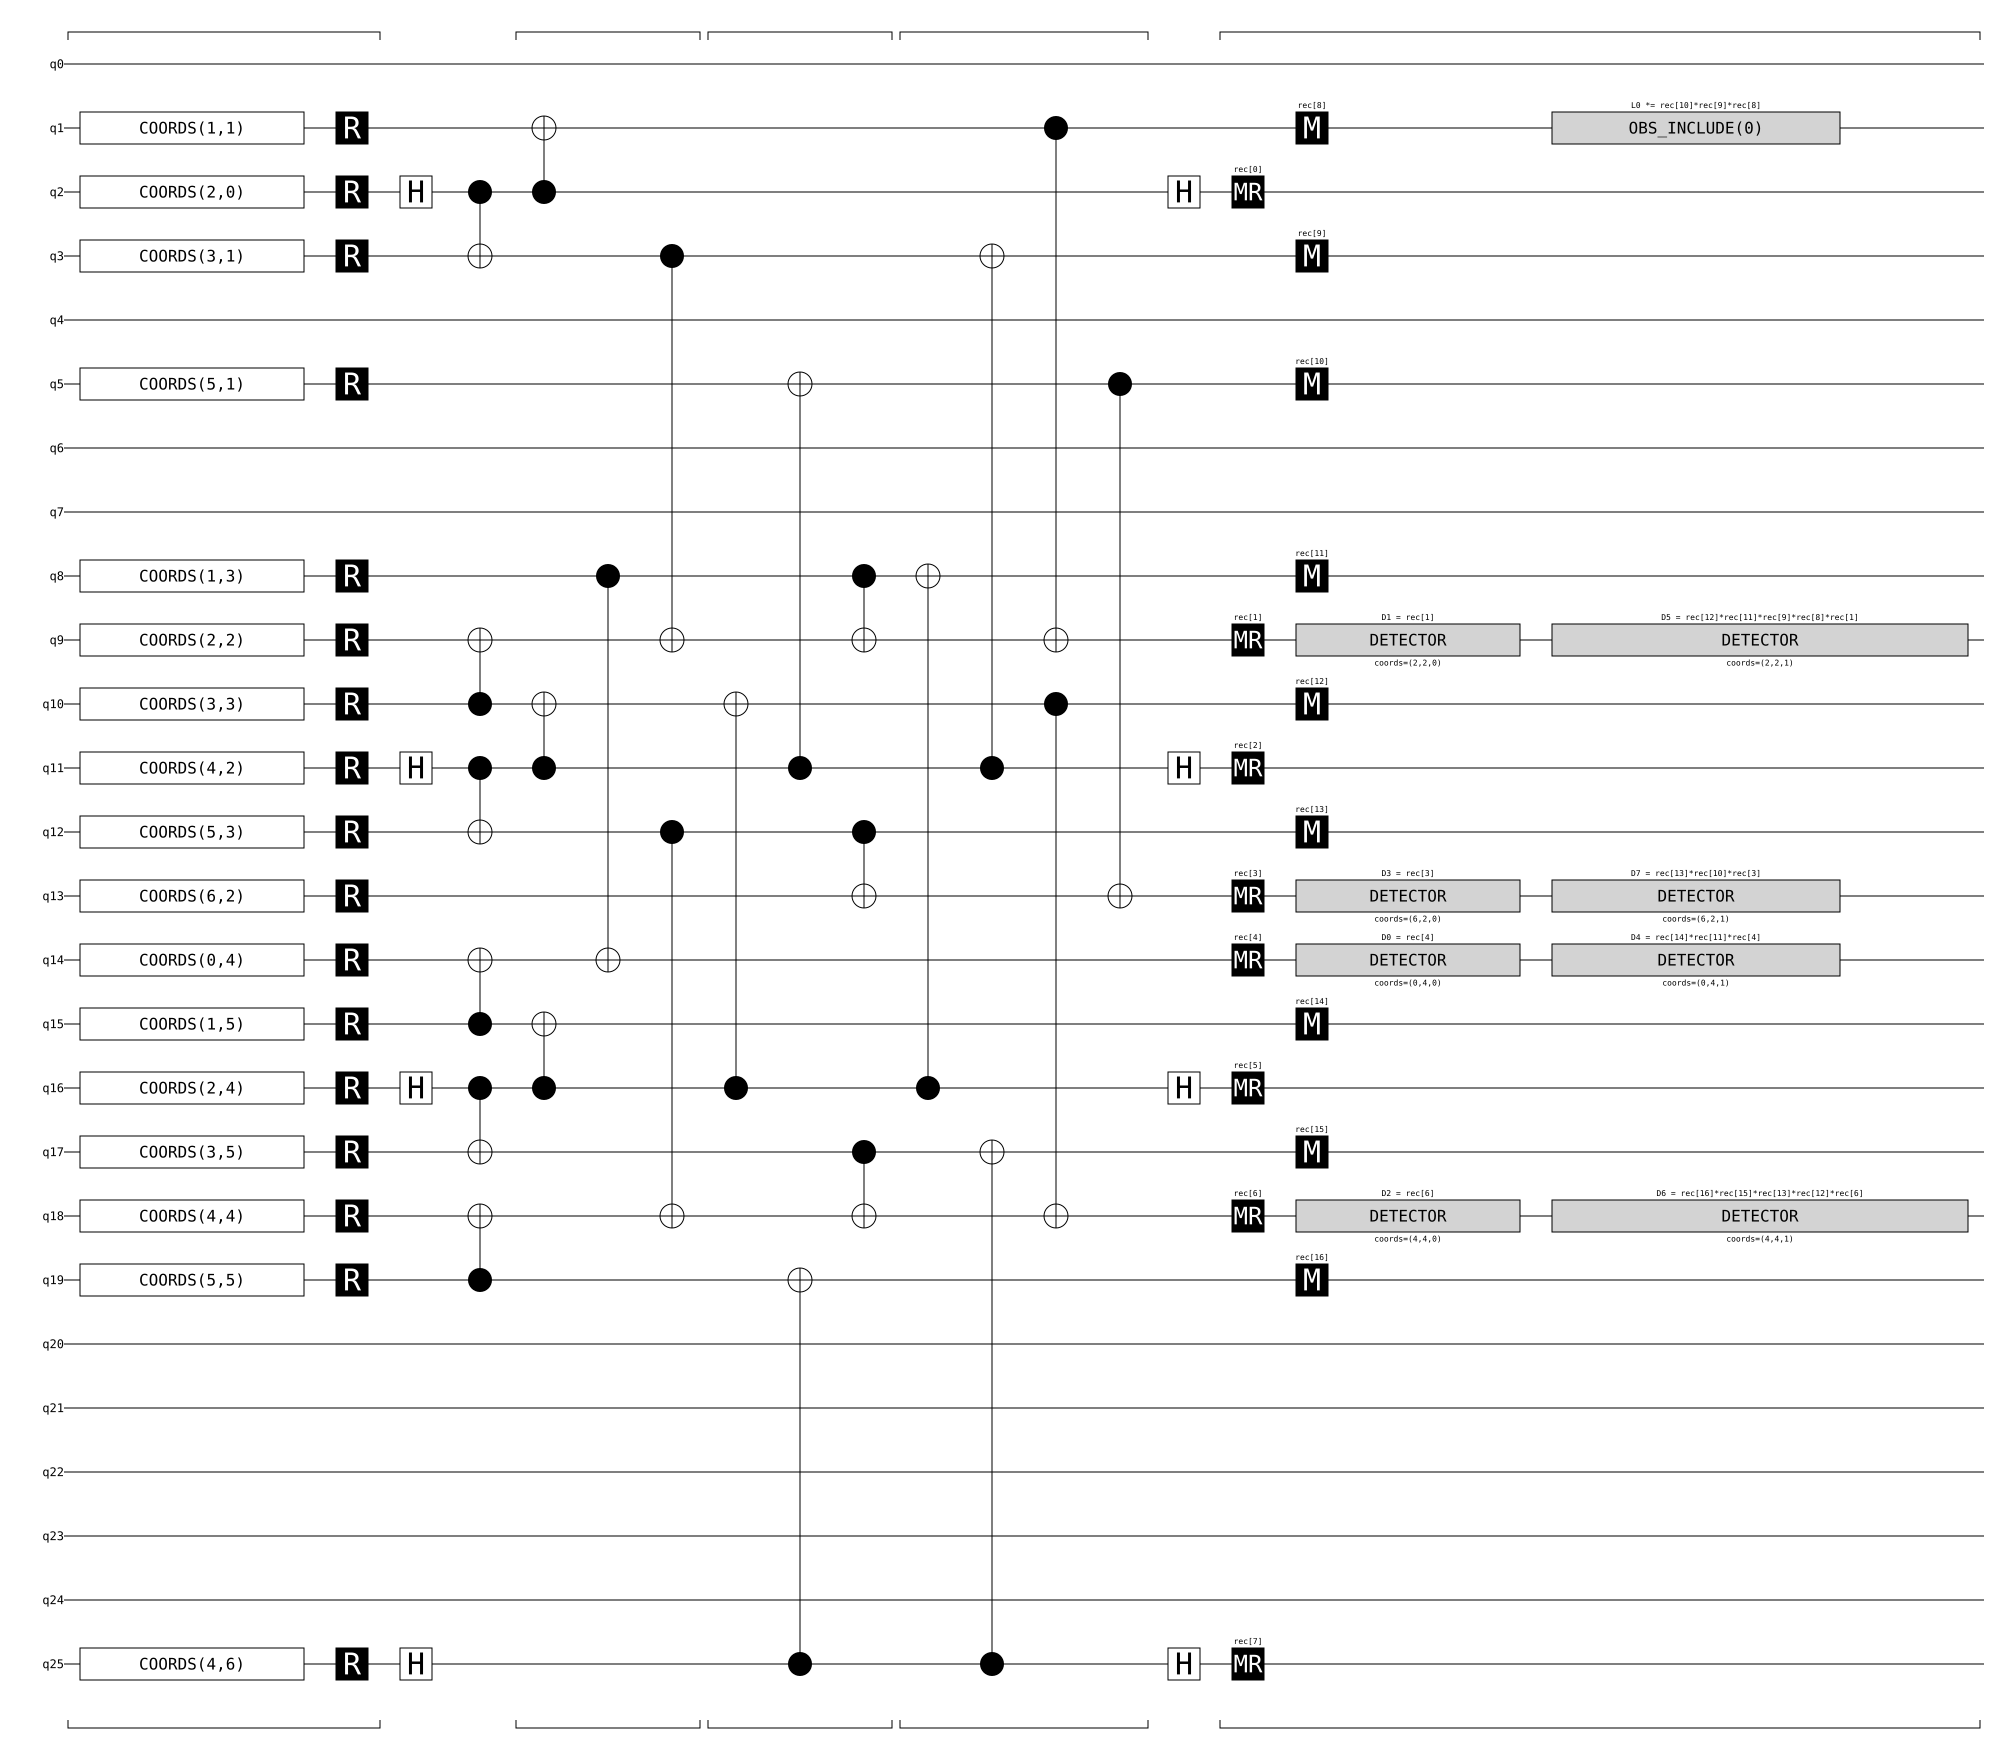

In [4]:
surface_code_circuit.diagram('timeline-svg')

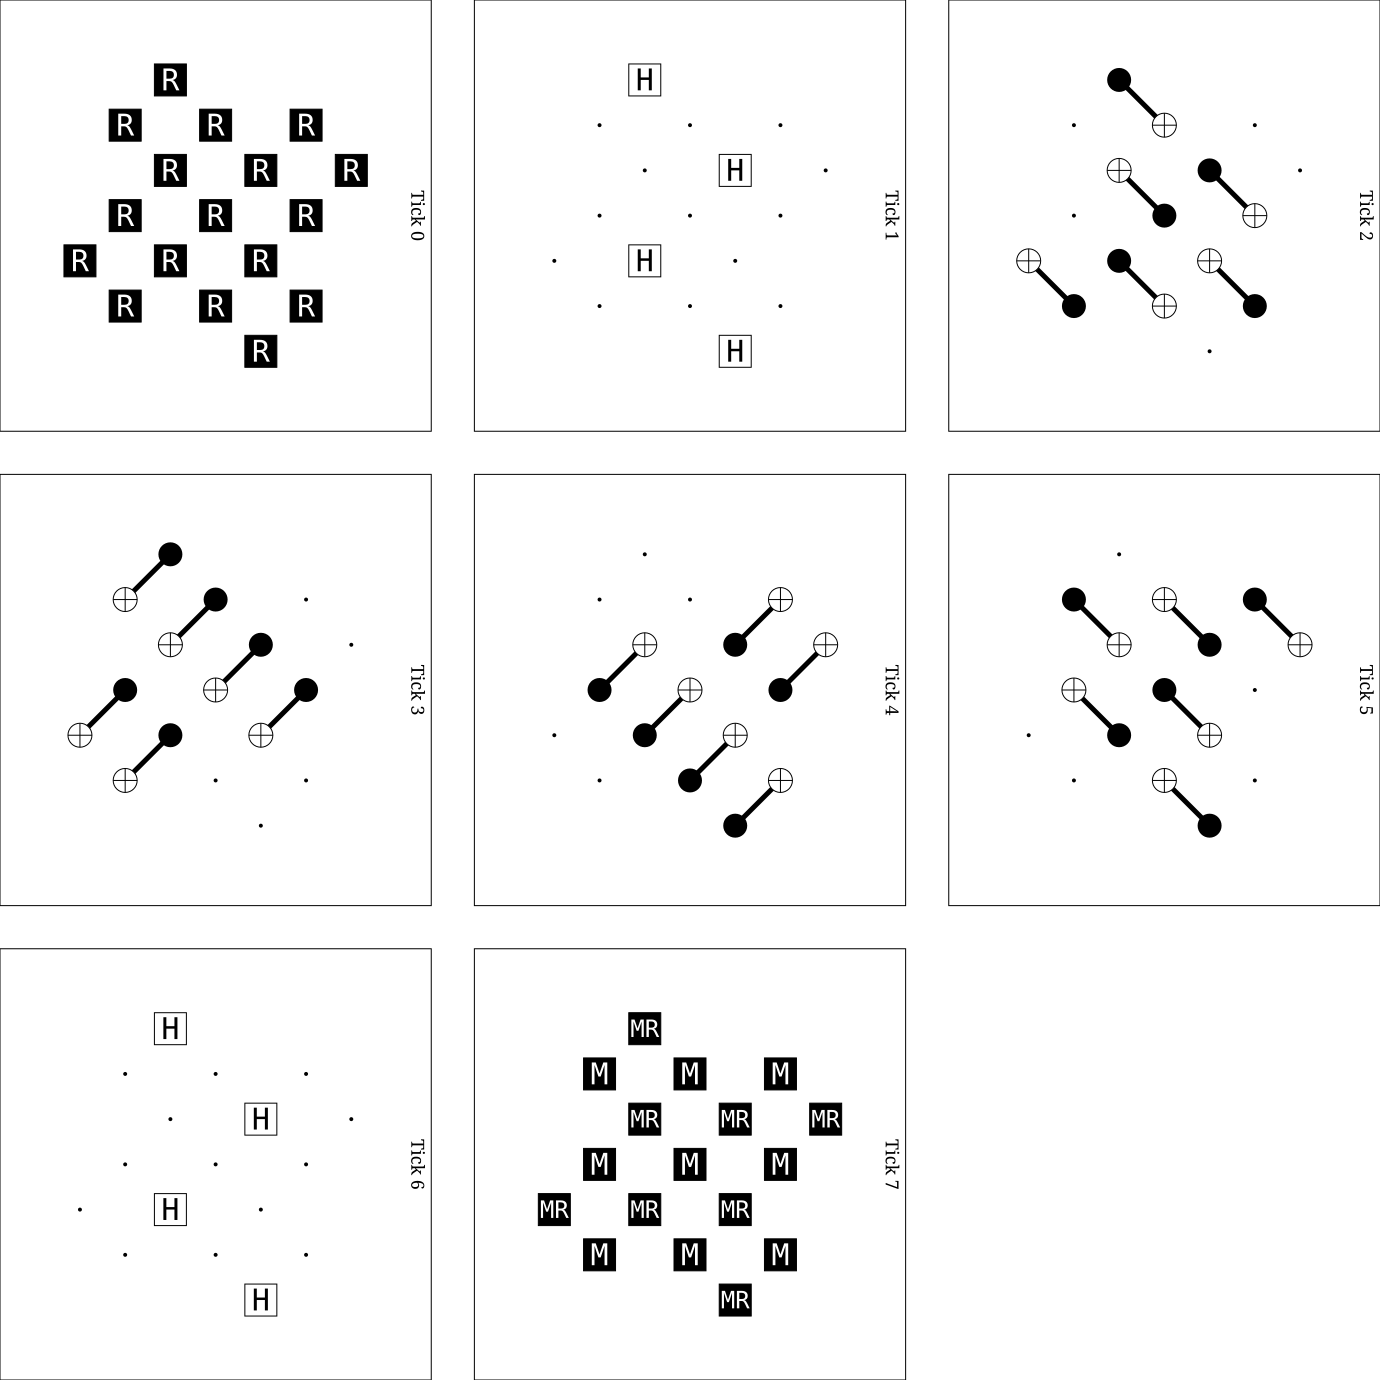

In [5]:
surface_code_circuit.without_noise().diagram("timeslice-svg")

# Manual Method for 1 round of d=3 surface code

In [6]:
def my_d3_rotated_memory_z():
    
    c = stim.Circuit()

    # Qubit layout

    coords = {
        1:  (1, 1),
        2:  (2, 0),
        3:  (3, 1),
        5:  (5, 1),
        8:  (1, 3),
        9:  (2, 2),
        10: (3, 3),
        11: (4, 2),
        12: (5, 3),
        13: (6, 2),
        14: (0, 4),
        15: (1, 5),
        16: (2, 4),
        17: (3, 5),
        18: (4, 4),
        19: (5, 5),
        25: (4, 6),
    }

    for q, (x, y) in coords.items():
        
        c.append("QUBIT_COORDS", [q], [x, y])

    # 9 data qubits IN THIS ORDER
    data = [1, 3, 5, 8, 10, 12, 15, 17, 19]

    # 8 stabilizer ancillas IN THIS ORDER
    ancillas = [2, 9, 11, 13, 14, 16, 18, 25]

    # X-stabilizer ancillas
    x_ancillas = [2, 11, 16, 25]

    # ------------------------------------------------------------
    # 2. # Initialize all physical qubits in |0>.
         # The first stabilizer round prepares the logical Z state,
         # tracking random X-check outcomes in a Pauli frame.
    # ------------------------------------------------------------

    # Z-basis reset of all data and ancilla qubits.
    c.append("R", data + ancillas)

    # ------------------------------------------------------------
    # 3. One stabilizer measurement round
    # ------------------------------------------------------------

    c.append("TICK")

    # Prepare X-check ancillas in |+>
    c.append("H", x_ancillas)

    # Four CNOT layers.
    #
    # For X checks: ancilla -> data
    # For Z checks: data -> ancilla

    c.append("TICK")
    c.append("CX", [
        2, 3,
        16, 17,
        11, 12,
        15, 14,
        10, 9,
        19, 18,
    ])

    c.append("TICK")
    c.append("CX", [
        2, 1,
        16, 15,
        11, 10,
        8, 14,
        3, 9,
        12, 18,
    ])

    c.append("TICK")
    c.append("CX", [
        16, 10,
        11, 5,
        25, 19,
        8, 9,
        17, 18,
        12, 13,
    ])

    c.append("TICK")
    c.append("CX", [
        16, 8,
        11, 3,
        25, 17,
        1, 9,
        10, 18,
        5, 13,
    ])

    # Rotate X-check ancillas back into Z basis.
    c.append("TICK")
    c.append("H", x_ancillas)

    # Measure and reset all stabilizer ancillas.
    c.append("TICK")
    c.append("MR", ancillas)

    # ------------------------------------------------------------
    # 4. Detectors after the first syndrome round
    # ------------------------------------------------------------
    #
    # Because we initialized in logical Z, the Z stabilizers have
    # known +1 values immediately. The X stabilizers do not.
    #
    # MR order:
    #   q2 q9 q11 q13 q14 q16 q18 q25
    #   -8 -7 -6  -5  -4  -3  -2  -1

    c.append(
        "DETECTOR",
        [stim.target_rec(-4)],
        [0, 4, 0],
    )  # Z check q14

    c.append(
        "DETECTOR",
        [stim.target_rec(-7)],
        [2, 2, 0],
    )  # Z check q9

    c.append(
        "DETECTOR",
        [stim.target_rec(-2)],
        [4, 4, 0],
    )  # Z check q18

    c.append(
        "DETECTOR",
        [stim.target_rec(-5)],
        [6, 2, 0],
    )  # Z check q13

    # ------------------------------------------------------------
    # 5. Final Z-basis measurement of the data
    # ------------------------------------------------------------

    c.append("M", data)

    # ------------------------------------------------------------
    # 6. Final boundary detectors
    # ------------------------------------------------------------
    #
    # These compare the final data measurements against the
    # corresponding Z-stabilizer measurements from the syndrome round.

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-3),
            stim.target_rec(-6),
            stim.target_rec(-13),
        ],
        [0, 4, 1],
    )

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-5),
            stim.target_rec(-6),
            stim.target_rec(-8),
            stim.target_rec(-9),
            stim.target_rec(-16),
        ],
        [2, 2, 1],
    )

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-1),
            stim.target_rec(-2),
            stim.target_rec(-4),
            stim.target_rec(-5),
            stim.target_rec(-11),
        ],
        [4, 4, 1],
    )

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-4),
            stim.target_rec(-7),
            stim.target_rec(-14),
        ],
        [6, 2, 1],
    )

    # ------------------------------------------------------------
    # 7. Logical Z measurement
    # ------------------------------------------------------------
    #
    # Top row q1-q3-q5 is one representative of logical Z.
    #
    # Final data measurements were, in this order:
    # q1 q3 q5 q8 q10 q12 q15 q17 q19
    #
    # Therefore q1,q3,q5 are rec[-9], rec[-8], rec[-7].

    c.append(
        "OBSERVABLE_INCLUDE",
        [
            stim.target_rec(-7),
            stim.target_rec(-8),
            stim.target_rec(-9),
        ],
        0,
    )

    return c

In [7]:
# check if manual and stim circuits match

mine = my_d3_rotated_memory_z()

stim_version = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    distance=3,
    rounds=1,
)

print("Mine:")
print(mine)

print("\nStim:")
print(stim_version)

print("\nExact match:", mine == stim_version)

Mine:
QUBIT_COORDS(1, 1) 1
QUBIT_COORDS(2, 0) 2
QUBIT_COORDS(3, 1) 3
QUBIT_COORDS(5, 1) 5
QUBIT_COORDS(1, 3) 8
QUBIT_COORDS(2, 2) 9
QUBIT_COORDS(3, 3) 10
QUBIT_COORDS(4, 2) 11
QUBIT_COORDS(5, 3) 12
QUBIT_COORDS(6, 2) 13
QUBIT_COORDS(0, 4) 14
QUBIT_COORDS(1, 5) 15
QUBIT_COORDS(2, 4) 16
QUBIT_COORDS(3, 5) 17
QUBIT_COORDS(4, 4) 18
QUBIT_COORDS(5, 5) 19
QUBIT_COORDS(4, 6) 25
R 1 3 5 8 10 12 15 17 19 2 9 11 13 14 16 18 25
TICK
H 2 11 16 25
TICK
CX 2 3 16 17 11 12 15 14 10 9 19 18
TICK
CX 2 1 16 15 11 10 8 14 3 9 12 18
TICK
CX 16 10 11 5 25 19 8 9 17 18 12 13
TICK
CX 16 8 11 3 25 17 1 9 10 18 5 13
TICK
H 2 11 16 25
TICK
MR 2 9 11 13 14 16 18 25
DETECTOR(0, 4, 0) rec[-4]
DETECTOR(2, 2, 0) rec[-7]
DETECTOR(4, 4, 0) rec[-2]
DETECTOR(6, 2, 0) rec[-5]
M 1 3 5 8 10 12 15 17 19
DETECTOR(0, 4, 1) rec[-3] rec[-6] rec[-13]
DETECTOR(2, 2, 1) rec[-5] rec[-6] rec[-8] rec[-9] rec[-16]
DETECTOR(4, 4, 1) rec[-1] rec[-2] rec[-4] rec[-5] rec[-11]
DETECTOR(6, 2, 1) rec[-4] rec[-7] rec[-14]
OBSERVABLE_INCLUDE(0

# Introduce Code Capacity Noise, single-instance, after 1st round

In [8]:
def my_d3_rotated_memory_z(rounds=2, p=0.0):

    if rounds < 2:
        
        raise ValueError("Need at least two rounds to measure errors inserted after the first round")
    
    c = stim.Circuit()

    # Qubit layout

    coords = {
        1:  (1, 1),
        2:  (2, 0),
        3:  (3, 1),
        5:  (5, 1),
        8:  (1, 3),
        9:  (2, 2),
        10: (3, 3),
        11: (4, 2),
        12: (5, 3),
        13: (6, 2),
        14: (0, 4),
        15: (1, 5),
        16: (2, 4),
        17: (3, 5),
        18: (4, 4),
        19: (5, 5),
        25: (4, 6),
    }

    for q, (x, y) in coords.items():
        
        c.append("QUBIT_COORDS", [q], [x, y])

    # 9 data qubits IN THIS ORDER
    data = [1, 3, 5, 8, 10, 12, 15, 17, 19]

    # 8 stabilizer ancillas IN THIS ORDER
    ancillas = [2, 9, 11, 13, 14, 16, 18, 25]

    # X-stabilizer ancillas
    x_ancillas = [2, 11, 16, 25]

    # ------------------------------------------------------------
    # 2. # Initialize all physical qubits in |0>.
         # The first stabilizer round prepares the logical Z state,
         # tracking random X-check outcomes in a Pauli frame.
    # ------------------------------------------------------------

    # Z-basis reset of all data and ancilla qubits.
    c.append("R", data + ancillas)

    # ------------------------------------------------------------
    # 3. Repeated stabilizer measurement rounds
    # ------------------------------------------------------------

    for r in range(rounds):

        c.append("TICK")
        c.append("H", x_ancillas)

        c.append("TICK")
        c.append("CX", [
            2, 3,
            16, 17,
            11, 12,
            15, 14,
            10, 9,
            19, 18,
        ])

        c.append("TICK")
        c.append("CX", [
            2, 1,
            16, 15,
            11, 10,
            8, 14,
            3, 9,
            12, 18,
        ])

        c.append("TICK")
        c.append("CX", [
            16, 10,
            11, 5,
            25, 19,
            8, 9,
            17, 18,
            12, 13,
        ])

        c.append("TICK")
        c.append("CX", [
            16, 8,
            11, 3,
            25, 17,
            1, 9,
            10, 18,
            5, 13,
        ])

        c.append("TICK")
        c.append("H", x_ancillas)

        c.append("TICK")
        c.append("MR", ancillas)

        # --------------------------------------------------------
        # 4. Detectors
        # --------------------------------------------------------


        if r == 0:
            
            # First round: deterministic Z checks.
            for q in [14, 9, 18, 13]:
                i = ancillas.index(q)
                x, y = coords[q]

                c.append(
                    "DETECTOR",
                    [stim.target_rec(i - 8)],
                    [x, y, r],
                )

            # Apply one noise instance after preparation.
            c.append("TICK")
            c.append("DEPOLARIZE1", data, p)

        else:
            
            # Later rounds: compare consecutive syndromes.
            for i, q in enumerate(ancillas):
                x, y = coords[q]

                c.append(
                    "DETECTOR",
                    [
                        stim.target_rec(i - 8),
                        stim.target_rec(i - 16),
                    ],
                    [x, y, r],
                )



    # ------------------------------------------------------------
    # 5. Final Z-basis measurement of the data
    # ------------------------------------------------------------

    c.append("M", data)

    # ------------------------------------------------------------
    # 6. Final boundary detectors
    # ------------------------------------------------------------
    #
    # These compare the final data measurements against the
    # corresponding Z-stabilizer measurements from the syndrome round.

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-3),
            stim.target_rec(-6),
            stim.target_rec(-13),
        ],
        [0, 4, rounds],
    )

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-5),
            stim.target_rec(-6),
            stim.target_rec(-8),
            stim.target_rec(-9),
            stim.target_rec(-16),
        ],
        [2, 2, rounds],
    )

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-1),
            stim.target_rec(-2),
            stim.target_rec(-4),
            stim.target_rec(-5),
            stim.target_rec(-11),
        ],
        [4, 4, rounds],
    )

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-4),
            stim.target_rec(-7),
            stim.target_rec(-14),
        ],
        [6, 2, rounds],
    )

    # ------------------------------------------------------------
    # 7. Logical Z measurement
    # ------------------------------------------------------------
    #
    # Top row q1-q3-q5 is one representative of logical Z.
    #
    # Final data measurements were, in this order:
    # q1 q3 q5 q8 q10 q12 q15 q17 q19
    #
    # Therefore q1,q3,q5 are rec[-9], rec[-8], rec[-7].

    c.append(
        "OBSERVABLE_INCLUDE",
        [
            stim.target_rec(-7),
            stim.target_rec(-8),
            stim.target_rec(-9),
        ],
        0,
    )

    return c

In [9]:
# verify

mine = my_d3_rotated_memory_z(rounds=3, p=0.01)

stim_version = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    distance=3,
    rounds=3,
)  # Noisy-code comparison requires matching the noise placement separately.

print("Detectors:", mine.num_detectors) # for d = 3, expect 4+8*(3-1)+4 = 24. I.e. at temporal boundaries, only Z detectors available. 
# in bulk, both Z and X detector available.
print("Observables:", mine.num_observables) 
print("\n")
print("Code detector model:")
print(mine.detector_error_model(decompose_errors=True))

Detectors: 24
Observables: 1


Code detector model:
error(0.003344519141621982) D4
error(0.003344519141621982) D4 D6
error(0.003344519141621982) D4 D6 ^ D5 L0
error(0.003344519141621982) D4 ^ D5 L0
error(0.003344519141621982) D5 D8
error(0.003344519141621982) D5 D8 ^ D9
error(0.003344519141621982) D5 D10
error(0.003344519141621982) D5 D10 ^ D6 D9
error(0.006666666666666613) D5 L0
error(0.006666666666666613) D6
error(0.003344519141621982) D6 D9
error(0.003344519141621982) D6 ^ D7 L0
error(0.003344519141621982) D7 D10
error(0.003344519141621982) D7 D10 ^ D6
error(0.003344519141621982) D7 L0
error(0.003344519141621982) D8
error(0.006666666666666613) D9
error(0.003344519141621982) D9 D11
error(0.003344519141621982) D9 D11 ^ D10
error(0.003344519141621982) D9 ^ D8
error(0.006666666666666613) D10
error(0.003344519141621982) D11
error(0.003344519141621982) D11 ^ D10
detector(0, 4, 0) D0
detector(2, 2, 0) D1
detector(4, 4, 0) D2
detector(6, 2, 0) D3
detector(2, 0, 1) D4
detector(2, 2, 1) D5
de

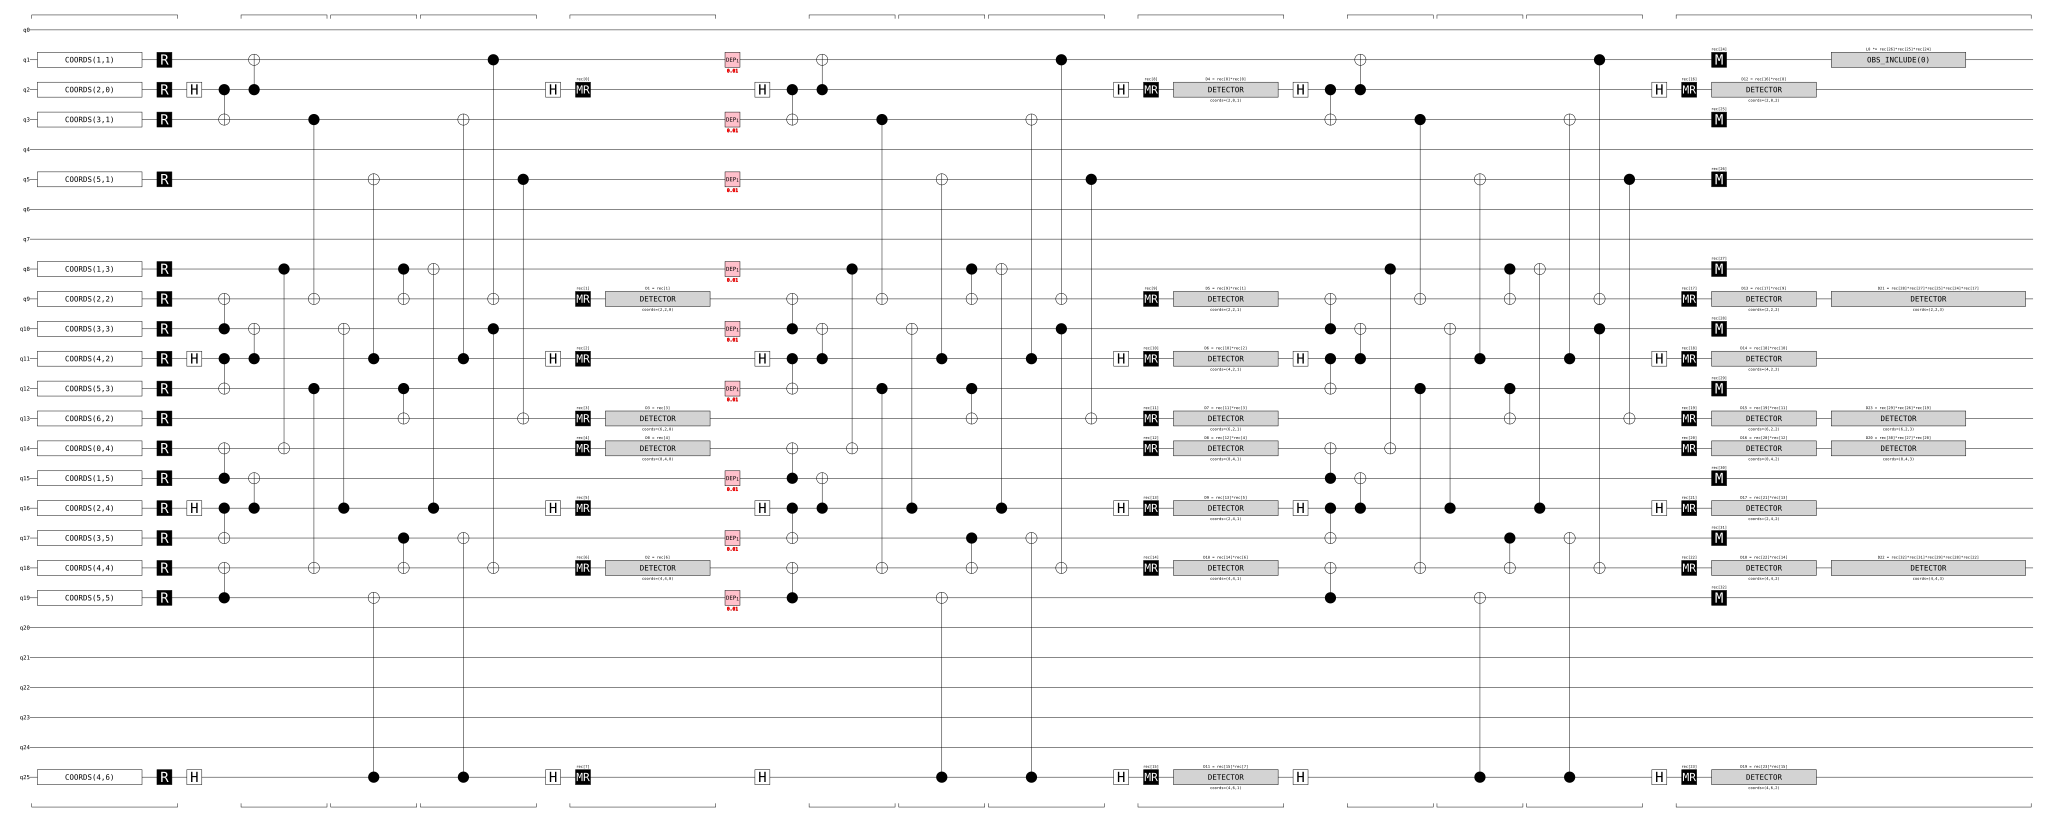

In [10]:
display(mine.diagram("timeline-svg"))

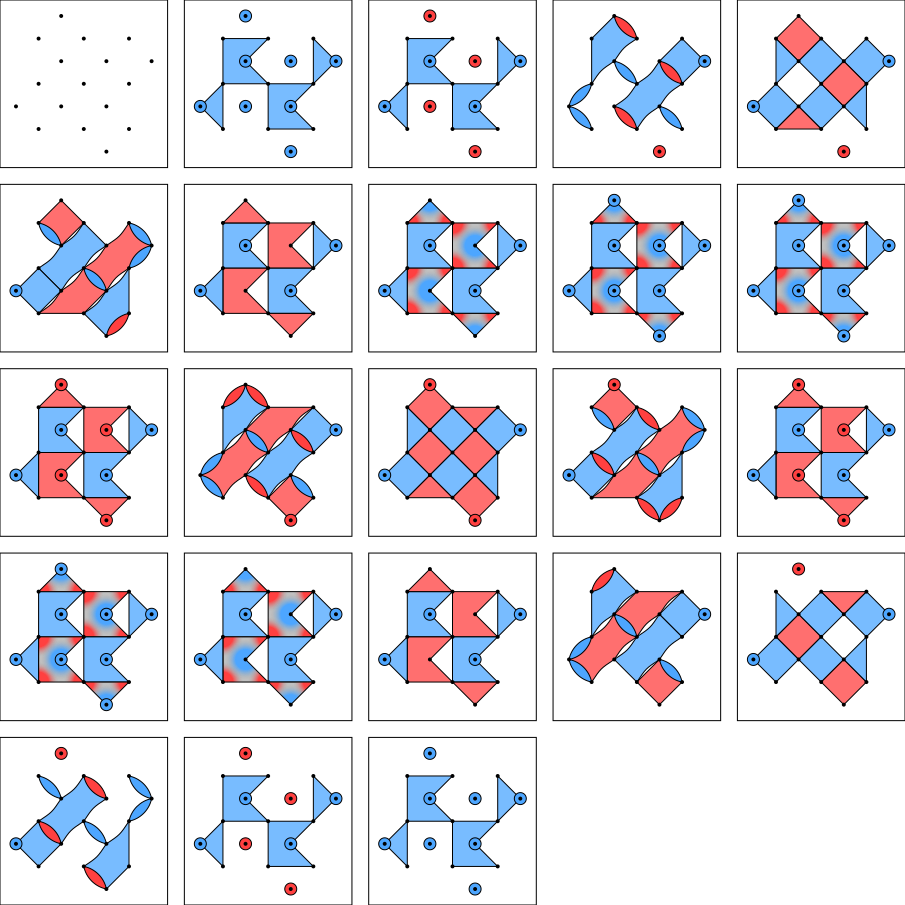

In [11]:
display(mine.diagram("detector-slice-svg"))

In [12]:
display(mine.diagram("matchgraph-3d"))

{"accessors":[{"bufferView":0,"byteOffset":0,"componentType":5126,"count":9,"max":[0,0.400000005960464,0.400000005960464],"min":[0,-0.400000005960464,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":1,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0,0.400000005960464],"min":[-0.400000005960464,0,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":2,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0.400000005960464,0],"min":[-0.400000005960464,-0.400000005960464,0],"name":"circle_loop","type":"VEC3"},{"bufferView":3,"byteOffset":0,"componentType":5126,"count":9,"max":[0,0.400000005960464,0.400000005960464],"min":[0,-0.400000005960464,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":4,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0,0.400000005960464],"min":[-0.400000005960464,0,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":5,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0.400000005960464,0],"min":[-0.400000005960464,-0.400000005960464,0],"name":"circle_loop","type":"VEC3"},{"bufferView":6,"byteOffset":0,"componentType":5126,"count":54,"max":[18.6666679382324,27.3704261779785,3],"min":[-9.3704252243042,-9.3704252243042,-0.333333492279053],"name":"buf_scattered_lines","type":"VEC3"},{"bufferView":7,"byteOffset":0,"componentType":5126,"count":10,"max":[27.3704261779785,6,3],"min":[-0.666666984558105,-0.666666984558105,-0.333333492279053],"name":"buf_red_scattered_lines","type":"VEC3"}],"asset":{"version":"2.0"},"bufferViews":[{"buffer":0,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":1,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":2,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":3,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":4,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":5,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":6,"byteLength":648,"byteOffset":0,"name":"buf_scattered_lines","target":34962},{"buffer":7,"byteLength":120,"byteOffset":0,"name":"buf_red_scattered_lines","target":34962}],"buffers":[{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAM3MzD4AAAAAAAAAAMPQkD7D0JA+AAAAAPIwlrLNzMw+AAAAAMPQkL7D0JA+AAAAAM3MzL7yMBazAAAAAMHQkL7E0JC+AAAAAPLkozHNzMy+AAAAAMbQkD6/0JC+AAAAAM3MzD4AAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAAAAAADNzMw+w9CQPgAAAADD0JA+zczMPgAAAADyMJayw9CQPgAAAADD0JC+8jAWswAAAADNzMy+xNCQvgAAAADB0JC+zczMvgAAAADy5KMxv9CQvgAAAADG0JA+AAAAAAAAAADNzMw+"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,zczMPgAAAAAAAAAAw9CQPsPQkD4AAAAA8jCWss3MzD4AAAAAw9CQvsPQkD4AAAAAzczMvvIwFrMAAAAAwdCQvsTQkL4AAAAA8uSjMc3MzL4AAAAAxtCQPr/QkL4AAAAAzczMPgAAAAAAAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAM3MzD4AAAAAAAAAAMPQkD7D0JA+AAAAAPIwlrLNzMw+AAAAAMPQkL7D0JA+AAAAAM3MzL7yMBazAAAAAMHQkL7E0JC+AAAAAPLkozHNzMy+AAAAAMbQkD6/0JC+AAAAAM3MzD4AAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAAAAAADNzMw+w9CQPgAAAADD0JA+zczMPgAAAADyMJayw9CQPgAAAADD0JC+8jAWswAAAADNzMy+xNCQvgAAAADB0JC+zczMvgAAAADy5KMxv9CQvgAAAADG0JA+AAAAAAAAAADNzMw+"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,zczMPgAAAAAAAAAAw9CQPsPQkD4AAAAA8jCWss3MzD4AAAAAw9CQvsPQkD4AAAAAzczMvvIwFrMAAAAAwdCQvsTQkL4AAAAA8uSjMc3MzL4AAAAAxtCQPr/QkL4AAAAAzczMPgAAAAAAAAAA"},{"byteLength":648,"name":"buf_scattered_lines","uri":"data:application/octet-stream;base64,AADAQAAAAAAAAEBA/Bg4QEPtFcH8GLg/AADAQAAAAAAAAEBAAABAQQAAwEAAAEBAAADAQAAAAAAAAEBAAABAQQAAwEAAAEBAAADAQAAAAAAAAEBA/Bg4QEPtFcH8GLg/AADAQAAAwEAAAEBAAAAAAAAAQEEAAEBAAADAQAAAwEAAAEBAAAAAAAAAQEEAAEBAAADAQAAAQEEAAEBAsKoqv1ZVlUGwqqq+

In [13]:
dem = mine.detector_error_model(decompose_errors=True)

for instruction in dem:
    print(instruction)

error(0.00334452) D4
error(0.00334452) D4 D6
error(0.00334452) D4 D6 ^ D5 L0
error(0.00334452) D4 ^ D5 L0
error(0.00334452) D5 D8
error(0.00334452) D5 D8 ^ D9
error(0.00334452) D5 D10
error(0.00334452) D5 D10 ^ D6 D9
error(0.00666667) D5 L0
error(0.00666667) D6
error(0.00334452) D6 D9
error(0.00334452) D6 ^ D7 L0
error(0.00334452) D7 D10
error(0.00334452) D7 D10 ^ D6
error(0.00334452) D7 L0
error(0.00334452) D8
error(0.00666667) D9
error(0.00334452) D9 D11
error(0.00334452) D9 D11 ^ D10
error(0.00334452) D9 ^ D8
error(0.00666667) D10
error(0.00334452) D11
error(0.00334452) D11 ^ D10
detector(0, 4, 0) D0
detector(2, 2, 0) D1
detector(4, 4, 0) D2
detector(6, 2, 0) D3
detector(2, 0, 1) D4
detector(2, 2, 1) D5
detector(4, 2, 1) D6
detector(6, 2, 1) D7
detector(0, 4, 1) D8
detector(2, 4, 1) D9
detector(4, 4, 1) D10
detector(4, 6, 1) D11
detector(2, 0, 2) D12
detector(2, 2, 2) D13
detector(4, 2, 2) D14
detector(6, 2, 2) D15
detector(0, 4, 2) D16
detector(2, 4, 2) D17
detector(4, 4, 2) D18
de

# Sinter for the above

Starting 12 workers...
11 tasks left:
  workers    decoder eta shots_left errors_left json_metadata
        1 pymatching <1m     973103        4981 d=3,p=0.01   
        1 pymatching   ?    1000000        5000 d=3,p=0.02   
        1 pymatching   ?    1000000        5000 d=3,p=0.03   
        1 pymatching   ?    1000000        5000 d=3,p=0.04   
        1 pymatching   ?    1000000        5000 d=3,p=0.05   
        1 pymatching   ?    1000000        5000 d=3,p=0.06   
        1 pymatching   ?    1000000        5000 d=3,p=0.08   
        1 pymatching   ?    1000000        5000 d=3,p=0.1    
        1 pymatching   ?    1000000        5000 d=3,p=0.12   
        1 pymatching   ?    1000000        5000 d=3,p=0.15   
        2 pymatching   ?    1000000        5000 d=3,p=0.2    
5 tasks left:
  workers    decoder        eta shots_left errors_left json_metadata
        3 pymatching        <1m      74179        4296 d=3,p=0.01   
        3 pymatching        <1m     333854        3010 d=3,p=0.02 

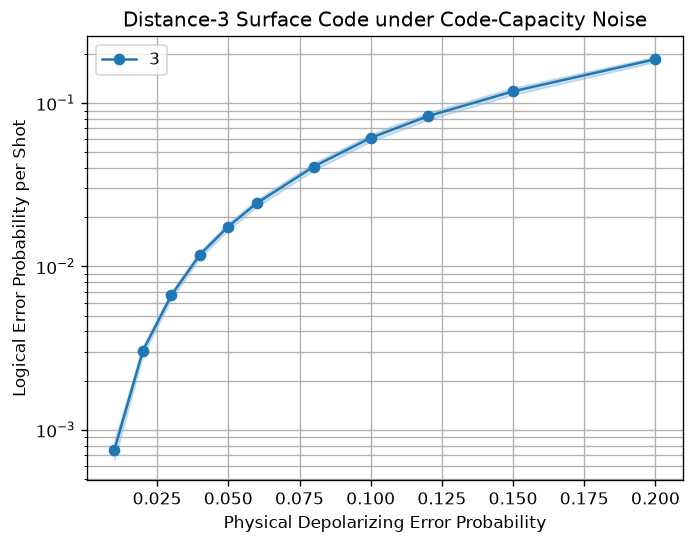

In [14]:

surface_code_tasks = [
    
    sinter.Task(
        circuit=my_d3_rotated_memory_z(rounds=2, p=noise),
        json_metadata={'d': 3, 'p': noise},
    )
    for noise in [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10, 0.12, 0.15, 0.20]
]

collected_surface_code_stats: List[sinter.TaskStats] = sinter.collect(
    num_workers=os.cpu_count(),
    tasks=surface_code_tasks,
    decoders=['pymatching'],
    max_shots=1_000_000,
    max_errors=5_000,
    print_progress=True,
)

# Plot
fig, ax = plt.subplots(1, 1)

sinter.plot_error_rate(
    ax=ax,
    stats=collected_surface_code_stats,
    x_func=lambda stat: stat.json_metadata['p'],
    group_func=lambda stat: stat.json_metadata['d'],
)

ax.set_title("Distance-3 Surface Code under Code-Capacity Noise")
ax.set_xlabel("Physical Depolarizing Error Probability")
ax.set_ylabel("Logical Error Probability per Shot")
ax.set_yscale("log")
ax.grid(which='major')
ax.grid(which='minor')
ax.legend()
fig.set_dpi(120)

plt.show()

# Generalize the manual rotated code to arbitrary odd distance

In [15]:
def my_rotated_memory_z(distance=3, p=0.0, rounds=2):
    
    """Manual rotated surface-code Z memory with one post-preparation noise instance."""
    
    if distance < 3 or distance % 2 != 1:
        
        raise ValueError('distance must be an odd integer >= 3')
        
    if rounds < 2:
        raise ValueError('Need a preparation round and a post-noise syndrome round')

    d = distance
    c = stim.Circuit()

    # Data sites have odd/odd coordinates. Check sites have even/even coordinates.
    data_xy = [(2*x+1, 2*y+1) for y in range(d) for x in range(d)]
    checks = []  # (x, y, Pauli type)

    # Four-body bulk checks, with alternating X and Z types.
    for y in range(1, d):
        
        for x in range(1, d):
            
            checks.append((2*x, 2*y, 'Z' if (x+y)%2 == 0 else 'X'))

    # Two-body boundary checks: X at top/bottom; Z at left/right.
    for x in range(1, d):
        
        checks.append((2*x, 0 if x%2 else 2*d, 'X'))
        
    for y in range(1, d):
        checks.append((0 if y%2 == 0 else 2*d, 2*y, 'Z'))

    checks.sort(key=lambda t: (t[1], t[0]))
    coord_to_q = {}
    
    for q, xy in enumerate(data_xy + [(x,y) for x,y,_ in checks]):
        
        coord_to_q[xy] = q
        c.append('QUBIT_COORDS', [q], list(xy))

    data = [coord_to_q[xy] for xy in data_xy]
    ancillas = [coord_to_q[(x,y)] for x,y,_ in checks]
    x_ancillas = [coord_to_q[(x,y)] for x,y,t in checks if t == 'X']
    z_check_indices = [i for i,(_,_,t) in enumerate(checks) if t == 'Z']

    # The two check types use different CNOT orderings to avoid hook errors.
    # Each (dx,dy) is a diagonal data position relative to the check center.

    x_order = [(1,1), (-1,1), (1,-1), (-1,-1)]
    z_order = [(1,1), (1,-1), (-1,1), (-1,-1)]
    layers = [[] for _ in range(4)]
    
    for x,y,t in checks:
        
        a = coord_to_q[(x,y)]
        
        for k,(dx,dy) in enumerate(x_order if t=='X' else z_order):
            
            q = coord_to_q.get((x+dx, y+dy))
            
            if q is not None:
                
                layers[k].extend([a,q] if t=='X' else [q,a])

    c.append('R', data + ancillas)
    n = len(ancillas)
    for r in range(rounds):
        c.append('TICK')
        c.append('H', x_ancillas)
        for layer in layers:
            c.append('TICK')
            if layer:
                c.append('CX', layer)
        c.append('TICK')
        c.append('H', x_ancillas)
        c.append('TICK')
        c.append('MR', ancillas)

        if r == 0:
            
            for i in z_check_indices:
                x,y,_ = checks[i]
                c.append('DETECTOR', [stim.target_rec(i-n)], [x,y,0])
            # Exactly one physical noise instance, after ideal state preparation.
            c.append('TICK')
            c.append('DEPOLARIZE1', data, p)
        else:
            for i,(x,y,_) in enumerate(checks):
                c.append('DETECTOR', [stim.target_rec(i-n),
                                      stim.target_rec(i-2*n)], [x,y,r])

    c.append('TICK')
    c.append('M', data)

    # Reconstruct the final Z check results from Z measurements of data.
    data_i = {xy:i for i,xy in enumerate(data_xy)}
    for i in z_check_indices:
        x,y,_ = checks[i]
        parity = [stim.target_rec(data_i[(x+dx,y+dy)]-len(data))
                  for dx in (-1,1) for dy in (-1,1)
                  if (x+dx,y+dy) in data_i]
        parity.append(stim.target_rec(i-n-len(data)))
        c.append('DETECTOR', parity, [x,y,rounds])

    # The top row is a representative logical Z operator.
    c.append('OBSERVABLE_INCLUDE',
             [stim.target_rec(data_i[(2*x+1,1)]-len(data)) for x in range(d)], 0)
    return c


# Sanity checks
An ideal run should produce no detector events or logical flips. 
For an odd distance d, there are $d^2$ data qubits, $d^2 - 1$ stabilizer checks, and $((d^2-1)/2) * 2 + (rounds-1)*(d^2-1)$ detectors.

In [16]:
for d in [3, 5, 7, 9, 11]:
    
    ideal = my_rotated_memory_z(distance=d, p=0, rounds=2)
    expected_detectors = 2 * ((d*d-1)//2) + (d*d-1)
    assert ideal.num_detectors == expected_detectors
    assert ideal.num_observables == 1
    det, obs = ideal.compile_detector_sampler().sample(shots=100, separate_observables=True)
    assert not det.any(), f"Unexpected detector event at d={d}"
    assert not obs.any(), f"Unexpected logical flip at d={d}"
    print(f"d={d}: PASS, detectors={ideal.num_detectors}")

# Also check that all noisy circuits admit a well-defined detector error model.
for d in [3, 5, 7, 9, 11]:
    
    dem = my_rotated_memory_z(distance=d, p=0.1, rounds=2).detector_error_model(decompose_errors=True)
    print(f"d={d}: {dem.num_detectors} DEM detectors, {dem.num_observables} observable(s)")

d=3: PASS, detectors=16
d=5: PASS, detectors=48
d=7: PASS, detectors=96
d=9: PASS, detectors=160
d=11: PASS, detectors=240
d=3: 16 DEM detectors, 1 observable(s)
d=5: 48 DEM detectors, 1 observable(s)
d=7: 96 DEM detectors, 1 observable(s)
d=9: 160 DEM detectors, 1 observable(s)
d=11: 240 DEM detectors, 1 observable(s)


# Sinter: manual-code code-capacity threshold plot

The crossing of logical-failure curves for increasing odd distances provides a finite-size estimate of the code-capacity threshold. \
These are Z-memory logical-bit-flip statistics for depolarizing data noise, decoded with PyMatching.

Starting 11 workers...
50 tasks left:
  workers    decoder        eta shots_left errors_left json_metadata
        1 pymatching          ?     100000        1000 d=3,p=0.04   
        1 pymatching          ?     100000        1000 d=3,p=0.06   
        1 pymatching          ?     100000        1000 d=3,p=0.08   
        1 pymatching          ?     100000        1000 d=3,p=0.1    
        1 pymatching          ?     100000        1000 d=3,p=0.12   
        1 pymatching [draining]      90511         -12 d=3,p=0.14   
        1 pymatching          ?     100000        1000 d=3,p=0.16   
        1 pymatching          ?     100000        1000 d=3,p=0.18   
        1 pymatching          ?     100000        1000 d=3,p=0.2    
        1 pymatching          ?     100000        1000 d=3,p=0.22   
        1 pymatching          ?     100000        1000 d=5,p=0.04   
        0 pymatching        ?·∞     100000        1000 d=5,p=0.06   
        0 pymatching        ?·∞     100000        1000 d=5,p=0.08

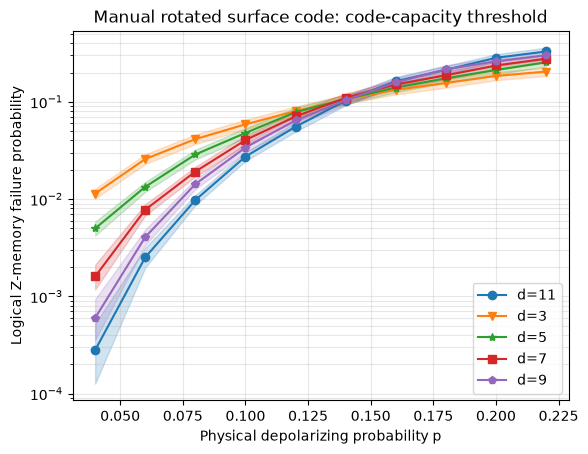

In [17]:
distances = [3, 5, 7, 9, 11]
noise_levels = [0.04, 0.06, 0.08, 0.10, 0.12, 0.14, 0.16, 0.18, 0.20, 0.22]

tasks = [
    
    sinter.Task(
        circuit=my_rotated_memory_z(distance=d, rounds=2, p=p),
        json_metadata={"d": d, "p": p},
    )
    for d in distances
    for p in noise_levels
]

stats = sinter.collect(
    num_workers=max(1, (os.cpu_count() or 2) - 1),
    tasks=tasks,
    decoders=["pymatching"],
    max_shots=100_000,
    max_errors=1_000,
    print_progress=True,
)

fig, ax = plt.subplots()
sinter.plot_error_rate(
    ax=ax,
    stats=stats,
    x_func=lambda s: s.json_metadata["p"],
    group_func=lambda s: f'd={s.json_metadata["d"]}',
)

ax.set(xlabel="Physical depolarizing probability p", ylabel="Logical Z-memory failure probability",
       title="Manual rotated surface code: code-capacity threshold")
ax.set_yscale("log")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

In [18]:
for d in [3, 5, 7, 9, 11]:
    
    c = my_rotated_memory_z(distance=d, p=0.01, rounds=2)

    dem = c.detector_error_model(decompose_errors=True)
    matching = pymatching.Matching.from_detector_error_model(dem)

    detectors, observables = c.compile_detector_sampler().sample(
        shots=10000,
        separate_observables=True,
    )

    predictions = matching.decode_batch(detectors)
    failures = (predictions != observables).any(axis=1)

    print(
        f"d={d}: logical error rate = {failures.mean():.6f}"
    )

d=3: logical error rate = 0.000600
d=5: logical error rate = 0.000200
d=7: logical error rate = 0.000000
d=9: logical error rate = 0.000000
d=11: logical error rate = 0.000000


# Compare manual functions

In [20]:
# compare manual functions

for rounds in [2, 3, 5, 7, 9, 11]:
    
    manual = my_d3_rotated_memory_z(rounds=rounds, p=0.01)
    general = my_rotated_memory_z(
        distance=3, rounds=rounds, p=0.01
    )

    print(
        f"rounds={rounds}: "
        f"manual={manual.num_detectors}, "
        f"general={general.num_detectors}"
    )

rounds=2: manual=16, general=16
rounds=3: manual=24, general=24
rounds=5: manual=40, general=40
rounds=7: manual=56, general=56
rounds=9: manual=72, general=72
rounds=11: manual=88, general=88


Next steps:
- Phenomenological noise
- Circuit noise
- Couple of plots to visualize partial gap on say a d=5 surface code
- logical error rate vs g
- rate of occurrence vs g
- Will roughly knows the behavior of these plots so they are checkable.

- Hook errors